# 05 Model comparison

Compares the baselines with tuned learned models using the same grouped 5-fold cross-validation, metrics and training participants as notebook 03.

**Input:** `data/processed/harth_windows.csv` (from `02_preprocessing.ipynb`)
**Output:** tuning results, results table (macro F1 and balanced accuracy, mean ± SD across folds, training and prediction time) and confusion matrices. The test participants are not used.

**Sections**
1. Setup: data, training participants and folds (same as notebook 03)
2. Baselines: dummy and logistic regression
3. k-NN
4. Decision tree
5. Random forest (TBC)
6. Gradient boosting (TBC)
7. Results table and comparison (TBC)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
print(Path.cwd())
# Create data directory 
data_directory = Path("../data/processed")
print(list(data_directory.iterdir()))

C:\Users\sarab\Projects\CT4101 ML Project\Machine_Learning_Portfolio_Project\notebooks
[WindowsPath('../data/processed/harth_windows.csv')]


In [3]:
# Read harth_windows csv file
harth_windows = pd.read_csv(data_directory/"harth_windows.csv")
harth_windows.head()

,back_x_mean,back_y_mean,back_z_mean,thigh_x_mean,thigh_y_mean,thigh_z_mean,back_mag_mean,thigh_mag_mean,back_x_sd,back_y_sd,...,back_x_range,back_y_range,back_z_range,thigh_x_range,thigh_y_range,thigh_z_range,back_mag_range,thigh_mag_range,activity,subject
0,-0.985535,0.076321,0.071897,-0.951721,0.066909,-0.300923,0.991294,1.000641,0.008179,0.015925,...,0.042021,0.106730,0.049085,0.026857,0.087156,0.065944,0.049257,0.030911,walking,S006
1,-0.990118,0.098939,0.052922,-0.970774,0.017955,-0.240916,0.996594,1.000600,0.006710,0.014250,...,0.021219,0.064559,0.039445,0.023676,0.082334,0.048104,0.021273,0.019548,standing,S006
2,-0.985489,0.114645,0.066351,-0.971958,0.013050,-0.227268,0.994405,0.998316,0.003794,0.007793,...,0.019534,0.039422,0.033895,0.007465,0.040694,0.031032,0.019653,0.008874,standing,S006
3,-0.986061,0.112886,0.061172,-0.971738,0.010761,-0.241171,0.994513,1.001399,0.004785,0.013871,...,0.021073,0.048442,0.034815,0.035844,0.036097,0.062481,0.023155,0.031511,standing,S006
4,-0.982235,0.143961,0.078188,-0.981988,0.051999,-0.167089,0.996508,1.000266,0.007308,0.028004,...,0.034060,0.127701,0.091557,0.051724,0.117495,0.212539,0.030263,0.033056,standing,S006


In [4]:
# Create a DataFrame with training data
TRAINING = ["S006", "S008", "S009", "S010", "S012", "S013", "S014", "S015", "S016", "S017", "S020", "S021", "S023", "S024", "S026", "S027", "S028", "S029"]

harth_windows_training = harth_windows[harth_windows["subject"].isin(TRAINING)]
harth_windows_training.shape

(96078, 26)

In [5]:
# Separate the inputs, target and groups
X = harth_windows_training.drop(columns=["activity", "subject"]) # inputs (24 features)
y = harth_windows_training["activity"] # target (activity column)
groups = harth_windows_training["subject"] # groups (who each row belongs to)

In [6]:
# 5 fold cross-validation with Stratified Group KFold
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

Baseline models from previous notebook for comparison later

In [7]:
# Dummy baseline to always predict the most common class (sitting)
model_dummy = DummyClassifier(strategy="most_frequent")
# Evaluate the dummy model with grouped 5-fold cross-validation
results_dummy = cross_validate(model_dummy, X, y, groups=groups, cv=cv, 
                               scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})

In [8]:
# Create Logistic regression baseline
model_logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
# Evaluate the logreg model with grouped 5-fold cross-validation
results_logreg = cross_validate(model_logreg, X, y, groups=groups, cv=cv, 
                                scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})

#### k-NN model

In [9]:
# Create kNN model 
model_knn = make_pipeline(StandardScaler(), 
                          KNeighborsClassifier())
# Try settings: number of neighbours, weights, and the distance measure
# (p=1 Manhattan, p=2 Euclidean)
param_grid_knn = {
"kneighborsclassifier__n_neighbors": [5, 15, 25, 45, 65],
"kneighborsclassifier__weights": ["uniform", "distance"],
"kneighborsclassifier__p": [1, 2],  
}

# Tune with same grouped 5-fold cross-validation as baselines.
# Use f1 to choose best settings
grid_knn = GridSearchCV(model_knn, param_grid_knn, cv=cv, 
                      scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
                       refit="f1")

grid_knn.fit(X, y, groups=groups)

# Best settings and mean macro F1 across the 5 folds
print(grid_knn.best_params_)
print(grid_knn.best_score_)

{'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'uniform'}
0.8082069518646335


In [10]:
# Scores for every combination tried
knn_results = pd.DataFrame(grid_knn.cv_results_)
knn_results[["param_kneighborsclassifier__n_neighbors", "param_kneighborsclassifier__weights", 
             "param_kneighborsclassifier__p", "mean_test_f1", "std_test_f1", "mean_test_balanced_accuracy"]]


,param_kneighborsclassifier__n_neighbors,param_kneighborsclassifier__weights,param_kneighborsclassifier__p,mean_test_f1,std_test_f1,mean_test_balanced_accuracy
0,5,uniform,1,0.805573,0.029447,0.803046
1,5,distance,1,0.802864,0.031583,0.797202
2,5,uniform,2,0.792069,0.054922,0.792447
3,5,distance,2,0.789821,0.056047,0.787775
4,15,uniform,1,0.808207,0.029984,0.798794
5,15,distance,1,0.807105,0.030987,0.796284
6,15,uniform,2,0.789574,0.054423,0.782638
7,15,distance,2,0.788591,0.054428,0.780440
8,25,uniform,1,0.805220,0.028926,0.793935
9,25,distance,1,0.804979,0.029704,0.792847


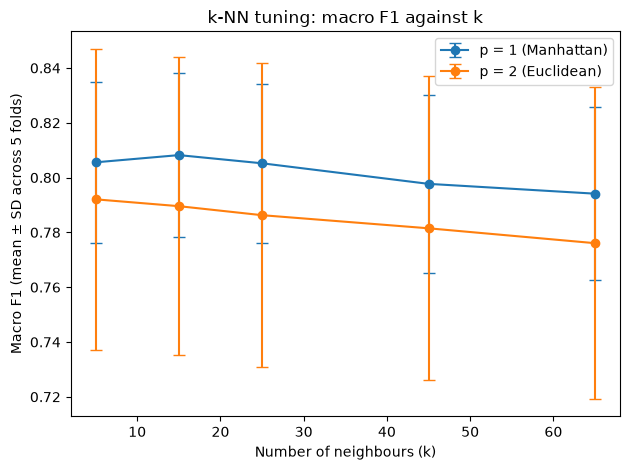

In [11]:
knn_uniform = knn_results[knn_results["param_kneighborsclassifier__weights"] == "uniform"]

for p, label in [(1, "p = 1 (Manhattan)"), (2, "p = 2 (Euclidean)")]:
    rows = knn_uniform[knn_uniform["param_kneighborsclassifier__p"] == p]
    plt.errorbar(rows["param_kneighborsclassifier__n_neighbors"], rows["mean_test_f1"],
                 yerr = rows["std_test_f1"], marker="o", capsize=4, label = label)
    
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Macro F1 (mean ± SD across 5 folds)")
plt.title("k-NN tuning: macro F1 against k")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Best k-NN model (k=15, uniform weights, Manhattan distance)
best_knn = grid_knn.best_estimator_

# Evaluate the tuned model with the same folds and metrics as other models
results_best_knn = cross_validate(best_knn, X, y, groups=groups, cv=cv,
                                  scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})
pred_best_knn = cross_val_predict(best_knn, X, y, groups=groups, cv=cv)

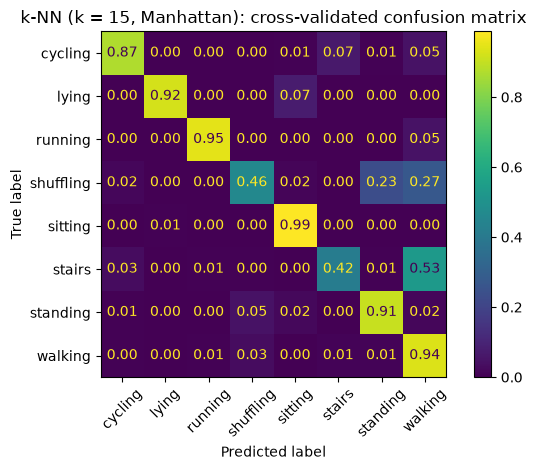

In [13]:
# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y, pred_best_knn, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("k-NN (k = 15, Manhattan): cross-validated confusion matrix")
plt.tight_layout()
plt.show()

In [14]:
# Model results function: Mean and standard deviation of each metric across the 5 folds
# plus mean training and prediction time per fold (in seconds)
def results_dict(name, results):
    mean_f1 = results["test_f1"].mean()
    sd_f1 = results["test_f1"].std()
    mean_balancedaccuracy = results["test_balanced_accuracy"].mean()
    sd_balancedaccuracy = results["test_balanced_accuracy"].std()
    mean_trainingtime = results["fit_time"].mean()
    mean_predictiontime = results["score_time"].mean()

    summary = { "Model": name,
                "Macro F1": f"{mean_f1:.3f} ± {sd_f1:.3f}",
                "Balanced Accuracy": f"{mean_balancedaccuracy:.3f} ± {sd_balancedaccuracy:.3f}",
                "Training Time (s)": f"{mean_trainingtime:.2f}",
                "Prediction Time": f"{mean_predictiontime:.2f}"}
    return(summary)

In [15]:
results_dummy_dict = results_dict("Dummy (most frequent)", results_dummy)
results_logreg_dict = results_dict("Logistic Regression", results_logreg)
results_knn_dict = results_dict("k-NN (k = 15, Manhattan)", results_best_knn) 

# Combine all models into one results table (mean ± SD across folds)
# One row per model
results_table = [results_dummy_dict, 
                 results_logreg_dict, 
                 results_knn_dict]
results_table = pd.DataFrame(results_table).set_index("Model")
results_table

,Macro F1,Balanced Accuracy,Training Time (s),Prediction Time
Model,,,,
Dummy (most frequent),0.081 ± 0.007,0.125 ± 0.000,0.05,0.09
Logistic Regression,0.809 ± 0.039,0.802 ± 0.036,3.15,0.11
"k-NN (k = 15, Manhattan)",0.808 ± 0.030,0.799 ± 0.047,0.18,12.37


- Tuned k (5 to 65), vote weighting (uniform, distance) and distance measure (p = 1 Manhattan, p = 2 Euclidean). Scaler needed inside the pipeline because k-NN uses distances.
- Best: k = 15, uniform weights, Manhattan distance. Macro F1 0.808 ± 0.030.
- Manhattan beat Euclidean at every k and was more stable across folds (SD about 0.03 vs 0.055). Since Euclidean distance squares differences, one feature with a large difference can dominate and cause higher SD.
- Weighting made almost no difference. k = 5 to 25 scored within 0.003 of each other.
- Compared with logistic regression: same overall score, but better on shuffling (0.46 vs 0.38) and stairs (0.42 vs 0.35), and worse on lying (0.92 vs 0.98, mistaken for sitting) and cycling. Possibly because k-NN weighs all 24 features equally, while logistic regression can learn that a few orientation features (like the back’s tilt) matter most for separating lying from sitting.
- Fast to train (0.18 s) but slowest to predict (12.6 s), because it searches the stored windows for every prediction.

#### Decision Tree

In [16]:
# Create Decision Tree model
model_tree = DecisionTreeClassifier(random_state=42)

# Try settings: max_depth, min_samples_leaf
param_grid_tree = {
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_leaf": [1, 10, 50, 100, 200],
    "criterion": ["gini", "entropy"]
}

# Tune with same grouped 5-fold cross-validation as baselines.
# Use f1 to choose best settings
grid_tree = GridSearchCV(model_tree, param_grid_tree, cv=cv, 
                        scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"},
                        refit="f1",
                        return_train_score=True,
                        n_jobs=-1)

grid_tree.fit(X, y, groups=groups)

# Best settings and mean macro F1 across the 5 folds
print(grid_tree.best_params_)
print(grid_tree.best_score_)

{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 50}
0.7758138258216084


In [17]:
# Scores for every combination tried
tree_results = pd.DataFrame(grid_tree.cv_results_)
tree_results[["param_max_depth", "param_min_samples_leaf", "param_criterion",
              "mean_train_f1", "mean_test_f1", "std_test_f1", "mean_test_balanced_accuracy"]]


,param_max_depth,param_min_samples_leaf,param_criterion,mean_train_f1,mean_test_f1,std_test_f1,mean_test_balanced_accuracy
0,None,1,gini,1.000000,0.737088,0.027407,0.758120
1,None,10,gini,0.921853,0.756846,0.017238,0.774313
2,None,50,gini,0.877868,0.757228,0.026529,0.777192
3,None,100,gini,0.856790,0.766687,0.044622,0.774112
4,None,200,gini,0.827165,0.762550,0.041149,0.766530
5,5,1,gini,0.712429,0.643910,0.069338,0.672876
6,5,10,gini,0.712072,0.644766,0.068213,0.673276
7,5,50,gini,0.710095,0.643285,0.070342,0.672786
8,5,100,gini,0.709858,0.642561,0.071979,0.672127
9,5,200,gini,0.707740,0.640778,0.070686,0.672567


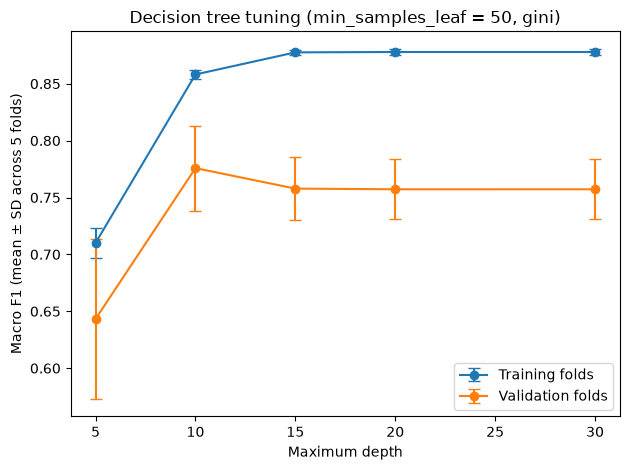

In [18]:
# Settings of the best tree, used to pick one line from the results
best_leaf = grid_tree.best_params_["min_samples_leaf"]
best_criterion = grid_tree.best_params_["criterion"]

# Keep the best leaf size and criterion, and drop max_depth=None (it can't go on a numeric axis)
tree_plot = tree_results[(tree_results["param_min_samples_leaf"] == best_leaf) &
                         (tree_results["param_criterion"] == best_criterion) &
                         (tree_results["param_max_depth"].notna())]

# Training vs validation macro F1 against depth: the gap shows overfitting
plt.errorbar(tree_plot["param_max_depth"], tree_plot["mean_train_f1"],
             yerr=tree_plot["std_train_f1"], marker="o", capsize=4, label="Training folds")
plt.errorbar(tree_plot["param_max_depth"], tree_plot["mean_test_f1"],
             yerr=tree_plot["std_test_f1"], marker="o", capsize=4, label="Validation folds")

plt.xlabel("Maximum depth")
plt.ylabel("Macro F1 (mean ± SD across 5 folds)")
plt.title(f"Decision tree tuning (min_samples_leaf = {best_leaf}, {best_criterion})")
plt.legend()
plt.tight_layout()
plt.show()


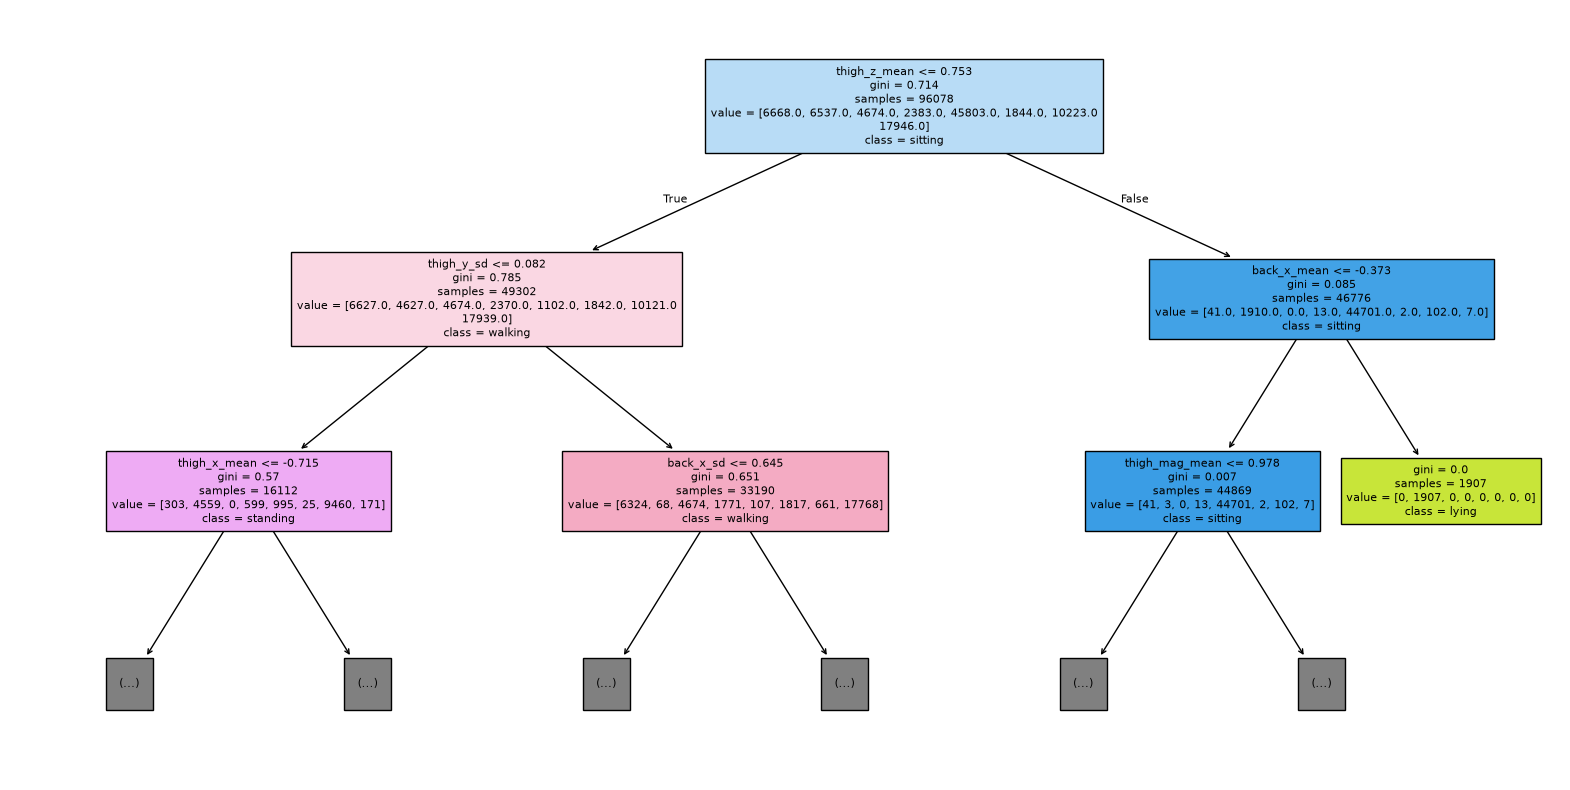

In [19]:
# Best Decision tree model (max_depth = 10, min_samples_leaf = 50, criterion = gini)
best_tree = grid_tree.best_estimator_

# Draw the top 2 levels of the best tree
plt.figure(figsize=(20, 10))
plot_tree(best_tree, feature_names=X.columns, class_names=best_tree.classes_,
          filled=True, max_depth=2, fontsize=8)
plt.show()

In [20]:
# Evaluate the tuned model with the same folds and metrics as other models
results_best_tree = cross_validate(best_tree, X, y, groups=groups, cv=cv,
                                   scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})
pred_best_tree = cross_val_predict(best_tree, X, y, groups=groups, cv=cv)

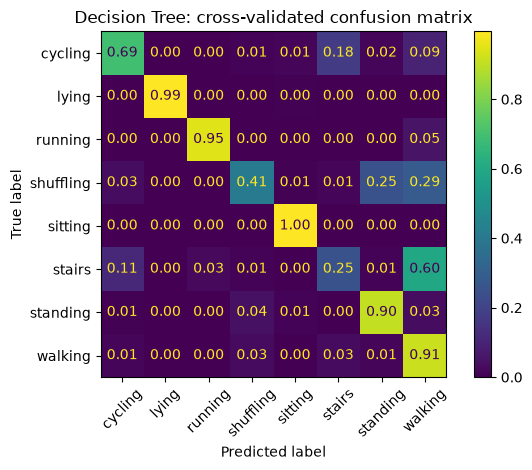

In [21]:
# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(y, pred_best_tree, normalize="true", values_format=".2f", xticks_rotation=45)
plt.title("Decision Tree: cross-validated confusion matrix")
plt.tight_layout()
plt.show()

In [22]:
results_tree_dict = results_dict("Decision Tree", results_best_tree) 
# Combine all models into one results table (mean ± SD across folds)
# One row per model
results_table = [results_dummy_dict, 
                 results_logreg_dict, 
                 results_knn_dict,
                results_tree_dict]
results_table = pd.DataFrame(results_table).set_index("Model")
results_table

,Macro F1,Balanced Accuracy,Training Time (s),Prediction Time
Model,,,,
Dummy (most frequent),0.081 ± 0.007,0.125 ± 0.000,0.05,0.09
Logistic Regression,0.809 ± 0.039,0.802 ± 0.036,3.15,0.11
"k-NN (k = 15, Manhattan)",0.808 ± 0.030,0.799 ± 0.047,0.18,12.37
Decision Tree,0.776 ± 0.037,0.775 ± 0.049,2.43,0.11


- Tuned max_depth (5 to 30, and no limit), min_samples_leaf (1 to 200) and criterion (gini, entropy). No scaler needed because trees split on thresholds.
- Best: gini, max_depth = 10, min_samples_leaf = 50. Macro F1 0.776 ± 0.037.
- Clear overfitting with no limits: training F1 1.000 vs validation 0.737. Underfitting at depth 5 (training 0.71, validation 0.64).
- With min_samples_leaf of 50 or more, depths of 15 and above give identical scores, because the leaf size stops the tree growing before the depth limit is reached.
- The top splits follow posture, then movement: thigh orientation (thigh_z_mean) first, back orientation (back_x_mean) to separate sitting from lying, and thigh movement variability (thigh_y_sd) to separate standing from walking.
- Weakest classes: stairs (0.25, mostly predicted as walking) and cycling (0.69, partly predicted as stairs). Lower overall than logistic regression and k-NN. This is expected for a single tree and I will try a random forest next.